In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm 
import statsmodels.formula.api as smf
from clickhouse_driver import Client
import joblib

## Задача:

#### Описание
Обновление дизайна карточки которая не менялась за последние 6 лет.  
Требовалось проследить за метрикой конверсии из просмотра карточки объявления в контакт, чтобы она не "упала".
Момент интервенции = с 2025-11-01

Изменения планировалось ввести сначала в одной платформе (mac), а затем на других, если гипотеза о том, что конверсия не упадет более чем на -10% относительно, подтвердится.

#### Данные

**Таблица** - Логи Яндекс Метрики
**Контакт** - Звонок/Сообщение по объявлению

In [ ]:
client = Client(host='host', port=9000, user='user', password='password', database='database')

In [ ]:
# подготовим функцию обращающуюся с запросом в clickhouse
def get_data(query):
    """
    Вытягивает данные из clickhouse в виде Dataframe

    query - запрос
    """
    result, columns = client.execute(query, with_column_types=True)
    return pd.DataFrame(result, columns=[tuple[0] for tuple in columns])

## 1 - Выгрузка
- 1.1. Средняя сумма контактов за день в Андроид
- 1.2. Средняя сумма просмотров за день в IOS

In [ ]:
# запрос в БД
query = r"""
select yha.ym_pv_datetime::date as event_date,
       case 
       	when yha.ym_pv_operatingsystem like '%windows%' then 'windows'
       	when yha.ym_pv_operatingsystem like '%linux%' then 'linux'
       	when yha.ym_pv_operatingsystem like '%ios%' then 'ios'
       	when yha.ym_pv_operatingsystem like '%android%' then 'android'
       	when yha.ym_pv_operatingsystem like '%mac%' then 'mac'
       end as platform,
       count(*) as cnt_view_advertisement,
       count(*) filter(where trim(TRANSLATE(yhe.ym_pv_goalsid, '[])`', ' ')) != '') as contact
  from ym.ym_hits_ad yha
  join ym.ym_hits_events yhe
    on yha.ym_pv_datetime = yhe.ym_pv_datetime
   and yha.ym_pv_watchid = yhe.ym_pv_watchid
   and yha.ym_pv_clientid = yhe.ym_pv_clientid
   and yha.ym_pv_counteruseridhash = yhe.ym_pv_counteruseridhash
  join ym.ym_hits_obshee yho
    on yha.ym_pv_datetime = yho.ym_pv_datetime
   and yha.ym_pv_watchid = yho.ym_pv_watchid
   and yha.ym_pv_clientid = yho.ym_pv_clientid
   and yha.ym_pv_counteruseridhash = yho.ym_pv_counteruseridhash
 where yha.ym_pv_datetime::date >= '2025-05-01'
   and yha.ym_pv_datetime::date < '2026-01-01'
   and yha.ym_pv_utmcampaign = 'apex_release'
   and yho.ym_pv_ispageview = 1
   and yha.ym_pv_operatingsystem is not null
 group by 1, 2
 order by 1
"""

data = get_data(query)

In [18]:
# загружаем данные по тесту
df = pd.read_csv('data/diff_in_diff.csv')
data = df[df.platform.isin(['mac', 'windows'])].copy()
data.head()

,event_date,platform,cnt_view_advertisement,contact
1,2025-05-19,mac,2,2
3,2025-05-20,mac,2,1
4,2025-05-20,windows,1,0
7,2025-05-21,mac,196,104
8,2025-05-21,windows,206,114


In [15]:
print('Средняя сумма контактов за день в windows' , round(data['contact'][data['platform'] == 'windows'].mean(), 0))

Средняя сумма контактов за день в windows 13.0


In [16]:
print('Средняя сумма просмотров за день в mac'  , round(data['cnt_view_advertisement'][data['platform'] == 'mac'].mean(), 0))

Средняя сумма просмотров за день в mac 36.0


Выгружаем данные за период 2025-05-15 - 2025-12-31 по платформам, сумму событии по кол-во просмотров объявления, и сумму кол-ва просмотров телефона и отправки сообщении как контакт

Задаем изменения с 2025-09-01 как treatment и выделяем платформу `mac` как тестовую группу - `intervention`

In [ ]:
# Преобразование датасета и создадание метрики отношения

data['event_date'] = pd.to_datetime(data['event_date'])
data['cr'] = data['contact'] / data['cnt_view_advertisement']
data['intervention'] = np.where(data.event_date >= '2025-11-01', 1, 0) # указываем, где у нас было нововведение
data['treatment'] = np.where(data.platform == 'mac', 1, 0) # указываем treatment (mac) и control (windows)
data

,event_date,platform,cnt_view_advertisement,contact,cr,intervention,treatment
1,2025-05-19,mac,2,2,1.000000,0,1
3,2025-05-20,mac,2,1,0.500000,0,1
4,2025-05-20,windows,1,0,0.000000,0,0
7,2025-05-21,mac,196,104,0.530612,0,1
8,2025-05-21,windows,206,114,0.553398,0,0
...,...,...,...,...,...,...,...
428,2025-12-22,windows,4,0,0.000000,1,0
429,2025-12-24,mac,1,1,1.000000,1,1
430,2025-12-25,windows,4,0,0.000000,1,0
431,2025-12-28,windows,2,0,0.000000,1,0


### График для визуализации

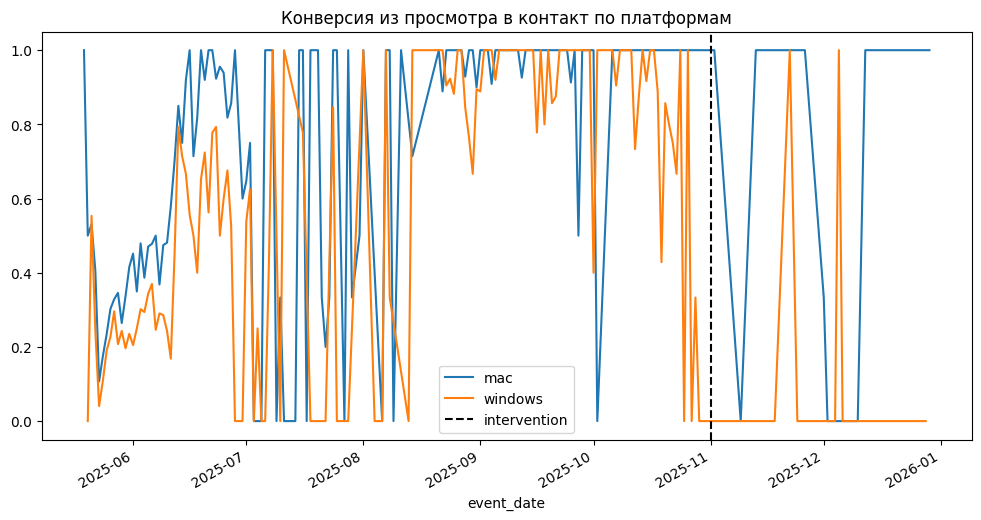

In [31]:
plt.title('Конверсия из просмотра в контакт по платформам')
data.set_index('event_date').groupby(['platform']).cr.plot(figsize = (12, 6))
plt.axvline(x = '2025-11-01', color = 'black', linestyle = '--', label = 'intervention')
plt.legend();

Можем оценить динамику изменения метрики до и после intervention в разрезе платформ

# Оценка паралельности трендов

C:\Users\2479\AppData\Local\Temp\ipykernel_13672\633647271.py:16: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  DF_pval = sm.tsa.stattools.adfuller(diff)[1]


P-value тест Дики-Фуллера = 0.027142
Средняя разница cr между mac и windows = 0.17
Разница между метрикой и ковариатой стационарна во времени? -> True


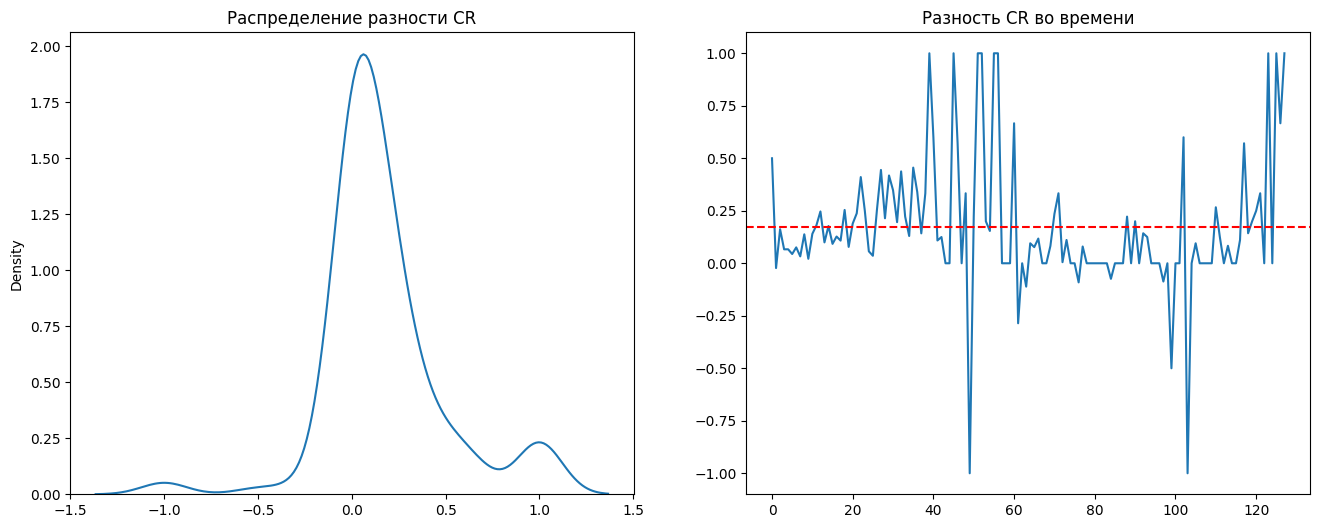

In [45]:
data["date_only"] = data["event_date"].dt.date
# фильтрация данных до интервенции
pre_period = data[data["event_date"] < pd.Timestamp("2025-11-01")]
# Агрегация CR по дням
mac_daily = (pre_period[pre_period["treatment"] == 1].groupby("date_only")["cr"].mean())
win_daily = (pre_period[pre_period["treatment"] == 0].groupby("date_only")["cr"].mean())

# Объединяем и удаляем возможные пропуски (дни, когда не было одной из платформ)
df_trends = pd.DataFrame({"mac": mac_daily, "windows": win_daily}).dropna()

# Считаем разницу
diff = (df_trends["mac"] - df_trends["windows"]).to_numpy()

# Проверка и визуализация
if len(diff) > 0:
    DF_pval = sm.tsa.stattools.adfuller(diff)[1]

    print("P-value тест Дики-Фуллера = %f" % DF_pval)
    print("Средняя разница cr между mac и windows =", round(abs(diff.mean()), 3))
    print("Разница между метрикой и ковариатой стационарна во времени? ->", DF_pval < 0.05,)

    # Визуализация
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    sns.kdeplot(ax=axes[0], data=diff)
    axes[0].set_title("Распределение разности CR")

    axes[1].plot(diff)
    axes[1].axhline(y=np.mean(diff), color="r", ls="--")
    axes[1].set_title("Разность CR во времени")

    plt.show()
else:
    print("Ошибка: массив разностей пуст. Проверьте, есть ли в данных даты до 2025-11-23!")


## Анализ с помощью Diff-in-Diff

In [47]:
formula = 'cr ~ treatment + intervention + treatment * intervention'
model = smf.ols(formula = formula, data = data)
res = model.fit()
print(res.summary())

                            OLS Regression Results                            
Dep. Variable:                     cr   R-squared:                       0.222
Model:                            OLS   Adj. R-squared:                  0.215
Method:                 Least Squares   F-statistic:                     30.65
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           1.86e-17
Time:                        15:18:43   Log-Likelihood:                -128.09
No. Observations:                 326   AIC:                             264.2
Df Residuals:                     322   BIC:                             279.3
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  0

In [ ]:
# Подтверждение гипотезы
p_value = res.pvalues['treatment:intervention']
if p_value < 0.05:
    print('H0 отвергается')
else:
    print('H0 не отвергается')

H0 отвергается


In [49]:
print('Diff-in-Diff =', round(res.params['treatment:intervention'], 5))

Diff-in-Diff = 0.45329


In [52]:
print('p-value =', round(p_value, 5))

p-value = 0.00031


## Оценка метрики ошибок
Провеcnb симуляцию ошибок 1 и 2 рода для эффектов [0.9, 0.95, 0.975, 1., 1.025, 1.05, 1.1]. 
Где 1 - нет эффекта

Используется следующие параметры для симуляции:
- ковариата - 'windows'
- n_days = 7,
- control_percent = 0.7
- n_sim = 100

In [57]:
def causal_analysis(data, control_group, n_days = 14, control_percent = 0.7, sample_n = 50):
    '''
    data - исторические данные, на которых нужно прогонять проверку критерия
    control_group - название переменной формирующих контрольную группу
    n_days - количество дней тестового периода. т.е. сколько предполагается держать пост-период в днях.
                Задавать нужно так чтобы размер n_days не превышал 1-control_percent долю тестовых данных. Поэтому процент 1-control_percent нужно оставлять с запасом
    control_percent - доля истрических данных, которые резервируются для контрольного периода. Например не меньше 70%.
    sample_n - кол-во симмуляций. Сколько раз прогонять на каждый проверяеммый эффект симмуляции (в коде по умолчанию 7 эффектов)

    '''
    n_days -= 1

    df_copy = data.copy()
    effects = [0.9, 0.95, 0.975, 1., 1.025, 1.05, 1.1] # Эффекты от снижения до увеличения. 1 - эффекта нет = АА вариант
    rel_effects = []

    dates = pd.DataFrame({'post_period_0': data.index}) # Даты

    # Самая первая дата контрольной группы
    initial = dates.values[0][0]
    # Тестовая группа, подбираем из неё sample_n рандомных дат в тестовом периоде, т.е. sample_n дат после control_percent дней.
    # Рандомно накидываем дни старта нововведения в тестовой зоне
    test = dates.iloc[int(len(dates)*(control_percent)):-n_days]\
                .sample(sample_n, random_state = 123, replace = True)\

    # Определяем пост и пре период в зависимости от полученных рандомных дат в тестовом периоде
    test['post_period_1'] = test.post_period_0 + pd.DateOffset(days = n_days)
    test['pre_period_0'] = initial
    test['pre_period_1'] = test.post_period_0 - pd.DateOffset(days = 1)

    test = test.astype(str)
    a = np.empty((sample_n, len(effects) + 2))

    def calculate_sse_mape_pval(d):
        sse = []
        mape = []
        p_vals = []
        for i in range(len(effects)):
            pre_period = [test.pre_period_0.values[d], test.pre_period_1.values[d]]
            post_period = [test.post_period_0.values[d], test.post_period_1.values[d]]

            # Формируем датасеты для оценки эффектов. Добавляем нужные эффекты
            df_copy = data.copy() # Создаём другую переменную дубликата датафрейма чтобы каждый раз задавать новый эффект

            # указываем когда был intervention
            df_copy['intervention'] = 0
            df_copy.loc[post_period[0]:post_period[1], 'intervention'] = 1

            df_copy.loc[np.logical_and(
                        df_copy.index >= post_period[0], df_copy.index <= post_period[1]), 'y'] *= effects[i] # задаём эффект

            df_copy = pd.melt(df_copy.reset_index(), id_vars = ['index', 'intervention'], value_vars = ['y', control_group],
                 var_name = 'variable', value_name = 'value')
            df_copy['treatment'] = np.where(df_copy.variable == 'y', 1, 0)

            formula = 'value ~ treatment + intervention + treatment * intervention'
            model = smf.ols(formula = formula, data = df_copy)
            res = model.fit()

            b0 = res.params['Intercept']
            b1 = res.params['treatment']
            b2 = res.params['intervention']
            b3 = res.params['treatment:intervention']

            # С регрессии вычисляем относительное изменение diff-in-diff
            rel_diff_in_diff = ((b0 + b1 + b2 + b3) / (b0 + b1)) / ((b0 + b2) / b0) - 1

            real_eff = effects[i] - 1
            to_sse = pow(rel_diff_in_diff - real_eff, 2) # считаем квадрат отклонкений найденного diff-in-diff и реального
            to_mape = abs(rel_diff_in_diff - real_eff) * 100 # считаем абсолютную ошибку найденного diff-in-diff и реального

            sse.append(to_sse)
            mape.append(to_mape)
            rel_effects.append(rel_diff_in_diff)
            p_vals.append(res.pvalues['treatment:intervention'])

        return (d, sum(sse), np.mean(mape), p_vals[effects.index(1)], p_vals[effects.index(1.025)],
               p_vals[effects.index(0.975)], p_vals[effects.index(1.05)], p_vals[effects.index(0.95)],
               p_vals[effects.index(1.1)], p_vals[effects.index(0.9)])

    results = joblib.Parallel(n_jobs=-1, verbose = len(test))(joblib.delayed(calculate_sse_mape_pval)(d) for d in range(len(test)))

    for result in results:
        d = result[0]
        a[d][0] = result[1]
        a[d][1] = result[2]
        a[d][2] = result[3]
        a[d][3] = result[4]
        a[d][4] = result[5]
        a[d][5] = result[6]
        a[d][6] = result[7]
        a[d][7] = result[8]
        a[d][8] = result[9]

    aa = pd.DataFrame(a, columns = ['sse', 'mape', 'p_val_1', 'p_val_1_025', 'p_val_0_975',
                                    'p_val_1_05', 'p_val_0_95', 'p_val_1_1', 'p_val_0_9'])
    final = test.reset_index().merge(aa.reset_index(), left_index = True, right_index = True)
    final.drop(columns = ['index_x', 'index_y'], inplace = True)
    final['control_group'] = control_group
    return final

Функция симуляции на исторических данных с синтетическими эффектами

In [58]:
ts_data = data.query("event_date < '2025-11-01'")\
              .pivot_table(values = 'cr', index = 'event_date', columns = 'platform')
ts_data.rename(columns = {'mac': 'y'}, inplace = True)
ts_data.index.name = None
ts_data

platform,y,windows
2025-05-19,1.000000,NaN
2025-05-20,0.500000,0.000000
2025-05-21,0.530612,0.553398
2025-05-22,0.406326,0.244027
2025-05-23,0.106969,0.040527
...,...,...
2025-10-27,1.000000,0.000000
2025-10-28,1.000000,0.333333
2025-10-29,NaN,0.000000
2025-10-30,1.000000,0.000000


Приводим данные в удобный вид

In [59]:
%%time
n_sim = 100
res = pd.DataFrame()
caus = causal_analysis(ts_data, 'windows', 7, 0.7, n_sim)
res = pd.concat([res, caus], axis = 0)
res

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 6 concurrent workers.
[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:    2.2s
[Parallel(n_jobs=-1)]: Done   2 tasks      | elapsed:    2.2s
[Parallel(n_jobs=-1)]: Done   3 tasks      | elapsed:    2.2s
[Parallel(n_jobs=-1)]: Done   4 tasks      | elapsed:    2.2s
[Parallel(n_jobs=-1)]: Done   5 tasks      | elapsed:    2.3s
[Parallel(n_jobs=-1)]: Done   6 tasks      | elapsed:    2.3s
[Parallel(n_jobs=-1)]: Done   7 tasks      | elapsed:    2.3s
[Parallel(n_jobs=-1)]: Done   8 tasks      | elapsed:    2.3s
[Parallel(n_jobs=-1)]: Done   9 tasks      | elapsed:    2.3s
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:    2.4s
[Parallel(n_jobs=-1)]: Done  11 tasks      | elapsed:    2.4s
[Parallel(n_jobs=-1)]: Done  12 tasks      | elapsed:    2.4s
[Parallel(n_jobs=-1)]: Done  13 tasks      | elapsed:    2.4s
[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed:    2.4s
[Parallel(n_jobs=-1)]: Done  15 tasks      | elapsed:   

,post_period_0,post_period_1,pre_period_0,pre_period_1,sse,mape,p_val_1,p_val_1_025,p_val_0_975,p_val_1_05,p_val_0_95,p_val_1_1,p_val_0_9,control_group
0,2025-09-17,2025-09-23,2025-05-19,2025-09-16,0.148032,14.514961,0.669408,0.763936,0.579875,0.862143,0.496424,0.936453,0.350790,windows
1,2025-10-13,2025-10-19,2025-05-19,2025-10-12,0.046188,8.107819,0.916932,0.982498,0.817684,0.882208,0.721292,0.688722,0.542496,windows
2,2025-10-19,2025-10-25,2025-05-19,2025-10-18,0.519822,27.199796,0.268286,0.217970,0.326101,0.174856,0.391503,0.108261,0.544194,windows
3,2025-10-23,2025-10-29,2025-05-19,2025-10-22,6.201282,93.946142,0.031944,0.023541,0.042814,0.017135,0.056680,0.008748,0.095747,windows
4,2025-10-02,2025-10-08,2025-05-19,2025-10-01,1.160702,40.644193,0.080888,0.096133,0.067667,0.113595,0.056278,0.155907,0.038252,windows
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,2025-09-20,2025-09-26,2025-05-19,2025-09-19,0.236901,18.362064,0.518088,0.602282,0.440461,0.692176,0.370001,0.884408,0.251651,windows
96,2025-10-25,2025-10-31,2025-05-19,2025-10-24,83.183125,344.077138,0.001314,0.000880,0.001941,0.000582,0.002834,0.000247,0.005840,windows
97,2025-10-07,2025-10-13,2025-05-19,2025-10-06,0.142564,14.244354,0.680062,0.775067,0.589908,0.873587,0.505723,0.924929,0.358402,windows
98,2025-09-30,2025-10-06,2025-05-19,2025-09-29,1.289737,42.843886,0.105248,0.120184,0.091823,0.136728,0.079810,0.175006,0.059615,windows


In [60]:
def to_res(data, to_group, n, alpha = 0.05):
    def p_val_count_alpha(p_val):
        return np.count_nonzero(p_val < alpha)

    def p_val_count_beta(p_val):
        return np.count_nonzero(p_val >= alpha)

    p_val_cols = data.filter(like = 'p_val').columns

    data['pre_period_diff'] = (pd.to_datetime(data.pre_period_1) - pd.to_datetime(data.pre_period_0))
    res = data.groupby([to_group]).agg({'sse': 'sum',
                                     'mape': 'mean',
                                     p_val_cols[0]: p_val_count_alpha,
                                     p_val_cols[1]: p_val_count_beta,
                                     p_val_cols[2]: p_val_count_beta,
                                     p_val_cols[3]: p_val_count_beta,
                                     p_val_cols[4]: p_val_count_beta,
                                     p_val_cols[5]: p_val_count_beta,
                                     p_val_cols[6]: p_val_count_beta,
                                     'pre_period_diff': 'mean'})

    res[p_val_cols[0]] = res[p_val_cols[0]] / n
    res[p_val_cols[1]] = res[p_val_cols[1]] / n
    res[p_val_cols[2]] = res[p_val_cols[2]] / n
    res[p_val_cols[3]] = res[p_val_cols[3]] / n
    res[p_val_cols[4]] = res[p_val_cols[4]] / n
    res[p_val_cols[5]] = res[p_val_cols[5]] / n
    res[p_val_cols[6]] = res[p_val_cols[6]] / n

    return res

In [61]:
# аггрегируем все симуляции
res_conc = to_res(res, 'control_group', n_sim)
res_conc

,sse,mape,p_val_1,p_val_1_025,p_val_0_975,p_val_1_05,p_val_0_95,p_val_1_1,p_val_0_9,pre_period_diff
control_group,,,,,,,,,,
windows,361.11576,38.021732,0.1,0.9,0.9,0.9,0.94,0.89,0.88,138 days 01:55:12


Можем посмотреть на метрику ошибок I рода которая здесь равна 0.00 и ошибку II рода для эффекта -5% которая равна 0.72

In [62]:
print('Ошибка II рода для -5% =', res_conc.p_val_0_95.values[0].round(3))
print('Ошибка I рода =', res_conc.p_val_1.values[0].round(3))

Ошибка II рода для -5% = 0.94
Ошибка I рода = 0.1
